# 📊 TP3 — Regressão linear simples e múltipla

## 1. Pergunta e escopo

**Pergunta numérica:** em que medida a quantidade de palavras e a pontuação ajudam a estimar o comprimento de uma mensagem, em caracteres?

Regressão linear é um modelo supervisionado que estima uma variável numérica por uma combinação linear de atributos. A versão simples usa um atributo; a múltipla usa dois ou mais. Aqui, o alvo é `char_count`, e não `intent`. O objetivo é praticar avaliação e diagnóstico antes de planejar a classificação de intenções em T2 (segundo trimestre).

O comprimento é calculável diretamente: não há vantagem operacional em estimá-lo depois de ler o texto. As relações entre medidas do mesmo texto são um exercício estatístico, sem interpretação causal ou evidência de classificação. A API continua com seu placeholder.

**Percurso:** qualidade dos dados → atributos → divisão por grupos → pipelines → métricas → resíduos → limitações. Veja o [resumo e reprodução](../docs/eda/tp3-regressao.md), a [EDA anterior](01_eda_ecomshield.ipynb) e o [glossário](../docs/glossario.md).

## 2. Ambiente e rastreabilidade

Execute este notebook com o Python do `venv/`, a partir de `notebooks/` ou da raiz do projeto. Instale antes `requirements.txt`. O CSV bruto não é versionado; obtenha-o na [fonte Bitext](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset). O hash abaixo identifica exatamente o arquivo local, sem expor mensagens.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, root_mean_squared_error

ROOT = Path.cwd() if (Path.cwd() / "notebooks").is_dir() else Path.cwd().parent
CSV = ROOT / "data/raw/bitext_intent.csv"
OUT = ROOT / "docs/eda"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 42
versions = {name: version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "nbclient"]}
print("Python:", platform.python_version())
print(json.dumps(versions, indent=2))
sha256 = hashlib.sha256(CSV.read_bytes()).hexdigest()
print("SHA-256 do CSV:", sha256)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

Python: 3.14.4
{
  "numpy": "2.5.2",
  "pandas": "3.0.5",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "matplotlib": "3.11.1",
  "nbclient": "0.11.0"
}
SHA-256 do CSV: 6f81102b0100b97b8468eb04368033a23206bf1fde9d53500d5806ec1001a434


## 3. Qualidade, limpeza e atributos

Inspecionamos ausentes, linhas duplicadas, textos vazios, textos repetidos e possíveis conflitos de rótulo. O processamento interrompe se houver mensagens ausentes, vazias ou não textuais: elas exigiriam uma decisão explícita, em vez de conversão silenciosa para texto. Preservamos o CSV e suas repetições para manter comparabilidade com a EDA. Não removemos comprimentos extremos apenas por serem raros.

| Variável | Papel | Cálculo e justificativa |
| --- | --- | --- |
| `char_count` | Alvo | Número de caracteres Unicode, incluindo espaços e pontuação |
| `word_count` | Atributo simples e múltiplo | Número de sequências não vazias separadas por espaços; acompanha o tamanho da mensagem |
| `punct_count` | Atributo adicional do múltiplo | Ocorrências de `! ? . , ; :`, seguindo a EDA; permite examinar contribuição adicional |

Os atributos são calculados por regras fixas, sem ajuste estatístico. Não usamos comprimento médio das palavras ou somas de tamanhos que, combinados, reconstruiriam o alvo por identidade algébrica. As colunas `response`, `intent`, `category` e `flags` não entram no modelo.

In [2]:
df = pd.read_csv(CSV)
text = df["instruction"]
quality = {
    "linhas": len(df),
    "colunas": len(df.columns),
    "ausentes_por_coluna": {k: int(v) for k, v in df.isna().sum().items()},
    "linhas_duplicadas": int(df.duplicated().sum()),
    "textos_repetidos": int(text.duplicated().sum()),
    "textos_vazios": int(text.str.strip().eq("").sum()),
    "textos_com_rotulos_conflitantes": int((df.groupby("instruction")["intent"].nunique() > 1).sum()),
}
print(json.dumps(quality, ensure_ascii=False, indent=2))
assert text.notna().all(), "Tratar mensagens ausentes antes de modelar."
assert text.map(lambda value: isinstance(value, str)).all(), "Há mensagens não textuais."
assert text.str.strip().ne("").all(), "Tratar mensagens vazias antes de modelar."
features = pd.DataFrame({
    "char_count": text.str.len(),
    "word_count": text.str.count(r"\S+"),
    "punct_count": text.str.count(r"[!?.,;:]"),
})
display(features.describe().round(3))

{
  "linhas": 26872,
  "colunas": 5,
  "ausentes_por_coluna": {
    "flags": 0,
    "instruction": 0,
    "category": 0,
    "intent": 0,
    "response": 0
  },
  "linhas_duplicadas": 0,
  "textos_repetidos": 2237,
  "textos_vazios": 0,
  "textos_com_rotulos_conflitantes": 0
}


,char_count,word_count,punct_count
count,26872.000,26872.000,26872.000
mean,46.890,8.691,0.259
std,10.898,2.605,0.510
min,6.000,1.000,0.000
25%,40.000,7.000,0.000
50%,48.000,9.000,0.000
75%,55.000,11.000,0.000
max,92.000,16.000,2.000


## 4. Treino e teste sem textos idênticos compartilhados

Usamos `GroupShuffleSplit` com semente 42 e 20% dos **grupos** para teste. Cada grupo contém um texto exato; por isso a proporção de linhas pode diferir de 20%. As repetições ficam no mesmo lado. Espaços, caixa e templates semelhantes não são normalizados nem agrupados: permanecem uma limitação.

A divisão não é estratificada por intenção, pois o alvo desta tarefa é numérico. Os mesmos índices são usados nas três avaliações. Não buscamos hiperparâmetros ou atributos com base no resultado do teste; ele é usado para a comparação didática previamente definida. Os diagnósticos posteriores não devem iniciar um ciclo de ajuste no mesmo teste.

In [3]:
X = features[["word_count", "punct_count"]]
y = features["char_count"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups=text))
train_groups = set(text.iloc[train_idx])
test_groups = set(text.iloc[test_idx])
assert train_groups.isdisjoint(test_groups), "Vazamento de textos idênticos."
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(df)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
split_info = {
    "semente": SEED,
    "linhas_treino": len(train_idx), "linhas_teste": len(test_idx),
    "grupos_treino": len(train_groups), "grupos_teste": len(test_groups),
    "grupos_compartilhados": len(train_groups & test_groups),
    "fracao_linhas_teste": len(test_idx) / len(df),
}
print(json.dumps(split_info, indent=2))
display(pd.DataFrame({"treino": y_train.describe(), "teste": y_test.describe()}).round(3))

{
  "semente": 42,
  "linhas_treino": 21466,
  "linhas_teste": 5406,
  "grupos_treino": 19708,
  "grupos_teste": 4927,
  "grupos_compartilhados": 0,
  "fracao_linhas_teste": 0.2011759452217922
}


,treino,teste
count,21466.000,5406.000
mean,46.917,46.781
std,10.933,10.755
min,8.000,6.000
25%,39.000,40.000
50%,48.000,48.000
75%,55.000,55.000
max,92.000,91.000


## 5. Pipelines e métricas

Um **pipeline** reúne transformações e estimador: `ColumnTransformer` seleciona atributos e `StandardScaler` centraliza e divide pelo desvio padrão do **treino**; depois `LinearRegression` ajusta mínimos quadrados. A escala não é necessária para mínimos quadrados neste caso, mas torna explícito como manter o pré-processamento ajustável dentro do treino. O mesmo ajuste é aplicado ao teste por `predict`, sem novo `fit`.

A regressão simples estima $\hat y=\beta_0+\beta_1 z_{palavras}$ e a múltipla estima $\hat y=\beta_0+\beta_1 z_{palavras}+\beta_2 z_{pontuação}$, onde $z$ é o atributo padronizado. O **baseline** `DummyRegressor` sempre prevê a média de caracteres do treino.

Para $n$ exemplos de teste, $e_i=y_i-\hat y_i$ é o resíduo:

$$R^2=1-\frac{\sum_i (y_i-\hat y_i)^2}{\sum_i(y_i-\bar y_{teste})^2},\qquad RMSE=\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}.$$

$R^2$ compara o erro quadrático ao uso da média do próprio teste; pode ser negativo e não é acurácia. RMSE (raiz do erro quadrático médio) mede erro em **caracteres** e penaliza mais os erros grandes. Não é uma margem máxima nem garante que cada previsão erre esse valor. O baseline usa média de treino, portanto seu $R^2$ no teste pode diferir de zero.

In [4]:
models = {"baseline_media": DummyRegressor(strategy="mean")}
for name, columns in {
    "linear_simples": ["word_count"],
    "linear_multipla": ["word_count", "punct_count"],
}.items():
    models[name] = Pipeline([
        ("preprocessamento", ColumnTransformer([
            ("numericos", StandardScaler(), columns)
        ], remainder="drop")),
        ("regressao", LinearRegression()),
    ])
rows, predictions = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    rows.append({
        "modelo": name,
        "r2_treino": r2_score(y_train, model.predict(X_train)),
        "r2_teste": r2_score(y_test, predictions[name]),
        "rmse_teste_caracteres": root_mean_squared_error(y_test, predictions[name]),
    })
metrics = pd.DataFrame(rows).set_index("modelo")
assert np.isfinite(metrics.to_numpy()).all()
display(metrics.round(6))

# Verificação independente das fórmulas, sem depender só das funções de métricas.
for name, pred in predictions.items():
    errors = y_test.to_numpy() - pred
    np.testing.assert_allclose(metrics.loc[name, "rmse_teste_caracteres"], np.sqrt(np.mean(errors**2)))
    np.testing.assert_allclose(metrics.loc[name, "r2_teste"], 1 - np.sum(errors**2) / np.sum((y_test - y_test.mean())**2))

,r2_treino,r2_teste,rmse_teste_caracteres
modelo,,,
baseline_media,0.000000,-0.000160,10.754452
linear_simples,0.660575,0.665791,6.216737
linear_multipla,0.661287,0.666675,6.208517


In [5]:
simple = metrics.loc["linear_simples"]
multiple = metrics.loc["linear_multipla"]
baseline = metrics.loc["baseline_media"]
display(Markdown(
    f"No teste, a regressão simples obteve **R²={simple.r2_teste:.4f}** e "
    f"**RMSE={simple.rmse_teste_caracteres:.3f} caracteres**; a múltipla obteve "
    f"**R²={multiple.r2_teste:.4f}** e **RMSE={multiple.rmse_teste_caracteres:.3f} caracteres**. "
    f"O baseline teve RMSE={baseline.rmse_teste_caracteres:.3f}. "
    f"A variação de RMSE (múltipla menos simples) foi "
    f"{multiple.rmse_teste_caracteres-simple.rmse_teste_caracteres:+.3f} caracteres. "
    "Esses resultados medem previsão de comprimento nesta divisão, sem demonstrar capacidade de prever intenções."
))
# Coeficientes na unidade original: efeito condicional estimado, não causal.
coef_rows = []
for name in ["linear_simples", "linear_multipla"]:
    model = models[name]
    prep = model.named_steps["preprocessamento"]
    scaler = prep.named_transformers_["numericos"]
    regression = model.named_steps["regressao"]
    raw_coef = regression.coef_ / scaler.scale_
    raw_intercept = regression.intercept_ - np.dot(raw_coef, scaler.mean_)
    columns = prep.transformers_[0][2]
    coef_rows.append({"modelo": name, "intercepto": raw_intercept, **dict(zip(columns, raw_coef))})
display(pd.DataFrame(coef_rows).set_index("modelo").round(4))

No teste, a regressão simples obteve **R²=0.6658** e **RMSE=6.217 caracteres**; a múltipla obteve **R²=0.6667** e **RMSE=6.209 caracteres**. O baseline teve RMSE=10.754. A variação de RMSE (múltipla menos simples) foi -0.008 caracteres. Esses resultados medem previsão de comprimento nesta divisão, sem demonstrar capacidade de prever intenções.

,intercepto,word_count,punct_count
modelo,,,
linear_simples,17.2046,3.4149,NaN
linear_multipla,17.0978,3.4449,-0.5898


## 6. Diagnóstico: residual plot e Q-Q plot

O **residual plot** coloca resíduos no eixo vertical e previsões no horizontal. Procuramos tendência/curvatura e mudanças de dispersão: nuvem sem padrão é compatível com boa especificação da média e variância aproximadamente constante (homocedasticidade), mas não prova esses pressupostos.

O **Q-Q plot** compara quantis empíricos dos resíduos aos quantis de uma normal. Padronizamos os resíduos pela média e desvio do próprio conjunto de diagnóstico, apenas para o gráfico; isso não altera previsões. A linha diagonal é a referência normal. Desvios nas caudas sugerem afastamento da normalidade; não significam automaticamente que o modelo não prevê. Normalidade é relevante à inferência clássica de intervalos e testes, que não realizamos aqui.

Usamos todos os resíduos do teste em ambos os modelos. A repetição de previsões decorre dos atributos de contagem. Exportamos também uma imagem independente do notebook para facilitar revisão.

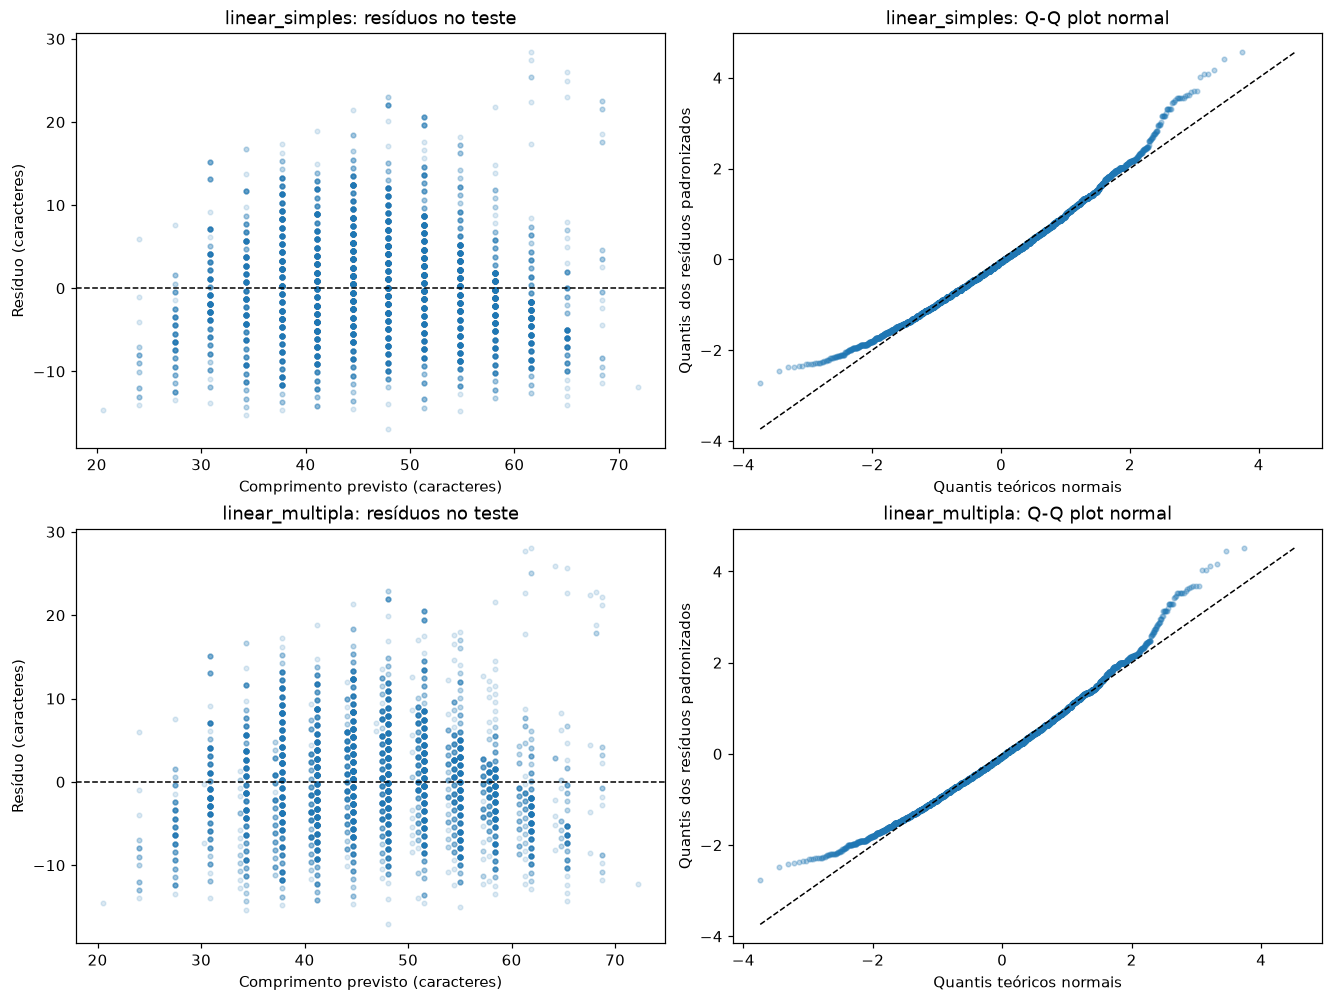

,media,desvio,assimetria,excesso_curtose,min_previsao,max_previsao
linear_simples,0.0290,6.2172,0.453,0.4431,20.6195,71.8435
linear_multipla,0.0242,6.2090,0.439,0.4286,20.5427,72.2160


linear_simples — resíduos por faixa de previsão


,size,mean,std
faixa,,,
"(20.619, 41.109]",1830,-0.5580,6.3097
"(41.109, 47.939]",1524,1.5620,6.1052
"(47.939, 54.769]",1221,0.5904,5.9691
"(54.769, 71.843]",831,-2.3148,5.6728


linear_multipla — resíduos por faixa de previsão


,size,mean,std
faixa,,,
"(20.541999999999998, 41.212]",1830,-0.5559,6.2749
"(41.212, 47.512]",977,1.6349,5.9003
"(47.512, 53.812]",1253,1.4034,6.2383
"(53.812, 72.216]",1346,-1.6402,5.7453


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
residual_tables = {}
residual_summary = {}
for row, name in enumerate(["linear_simples", "linear_multipla"]):
    pred = predictions[name]
    residual = y_test.to_numpy() - pred
    ax = axes[row, 0]
    ax.scatter(pred, residual, s=9, alpha=0.15, rasterized=True)
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="Comprimento previsto (caracteres)", ylabel="Resíduo (caracteres)",
           title=f"{name}: resíduos no teste")
    standardized = (residual - residual.mean()) / residual.std(ddof=1)
    normal_quantiles = stats.norm.ppf((np.arange(len(residual)) + 0.5) / len(residual))
    ax = axes[row, 1]
    ax.scatter(normal_quantiles, np.sort(standardized), s=9, alpha=0.3, rasterized=True)
    limits = [min(normal_quantiles.min(), standardized.min()), max(normal_quantiles.max(), standardized.max())]
    ax.plot(limits, limits, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="Quantis teóricos normais", ylabel="Quantis dos resíduos padronizados",
           title=f"{name}: Q-Q plot normal")
    residual_summary[name] = {
        "media": float(residual.mean()),
        "desvio": float(residual.std(ddof=1)),
        "assimetria": float(stats.skew(residual, bias=False)),
        "excesso_curtose": float(stats.kurtosis(residual, bias=False)),
        "min_previsao": float(pred.min()), "max_previsao": float(pred.max()),
    }
    diagnostic = pd.DataFrame({"previsto": pred, "residuo": residual})
    diagnostic["faixa"] = pd.qcut(diagnostic["previsto"], q=4, duplicates="drop")
    residual_tables[name] = diagnostic.groupby("faixa", observed=True)["residuo"].agg(["size", "mean", "std"])
fig.savefig(FIGURES / "tp3-residuos.png", dpi=160)
plt.show()
display(pd.DataFrame(residual_summary).T.round(4))
for name, table in residual_tables.items():
    print(name, "— resíduos por faixa de previsão")
    display(table.round(4))

### Leitura crítica dos diagnósticos

As interpretações visuais são registradas abaixo após a execução e inspeção da figura. As tabelas por faixa complementam a visualização: médias distantes de zero sugerem viés local e desvios diferentes indicam variância não constante. Isso é diagnóstico descritivo, sem teste formal de homocedasticidade ou normalidade. Os resíduos de teste são erros de generalização; não precisam somar zero como os resíduos do treino de mínimos quadrados com intercepto.

**Resultado observado:** nos dois residual plots, as faixas centrais têm resíduos médios positivos e a faixa de previsões maiores tem média negativa: há subestimação no centro e superestimação em parte dos textos previstos como longos. No múltiplo, as médias das quatro faixas são aproximadamente −0,556, +1,635, +1,403 e −1,640 caracteres. A média global próxima de zero (0,024) esconde esse viés local.

Os desvios por faixa do múltiplo vão de 5,745 a 6,275 caracteres. A dispersão varia moderadamente, mas a figura e essa comparação descritiva não bastam para afirmar homocedasticidade. As colunas de pontos refletem atributos discretos, e o modelo múltiplo preserva padrões semelhantes ao simples.

Nos Q-Q plots, o centro acompanha aproximadamente a diagonal; a cauda esquerda fica acima dela e a direita se eleva mais acentuadamente. Isso é compatível com assimetria positiva (0,439 no múltiplo) e afastamento da normalidade nas caudas. Não assumimos resíduos normais. O ganho do múltiplo é pequeno: redução de cerca de 0,008 caractere no RMSE, sem demonstrar relevância prática. O coeficiente condicional negativo de pontuação (−0,590) não significa que adicionar pontuação encurte causalmente um texto: é uma associação ajustada pelas palavras nesta amostra.

## 7. Limitações e próximos passos

1. **Alvo auxiliar:** estimar comprimento não resolve intenção. `intent` é categórica nominal: seus rótulos não têm ordem ou distância numérica. Codificá-los por inteiros e arredondar regressão imporia distâncias arbitrárias, e a saída contínua poderia nem corresponder a uma classe válida. Comprimentos semelhantes podem expressar intenções diferentes.
2. **Dependência estrutural:** palavras e pontuação fazem parte do texto cujo comprimento é o alvo; resultados altos medem essa associação mecânica. O ganho sobre a média não demonstra compreensão semântica nem causalidade. O intercepto extrapolado para zero palavras não tem interpretação operacional.
3. **Generalização limitada:** uma divisão agrupada impede textos exatos nos dois conjuntos, mas templates e paráfrases próximos podem atravessar a divisão. Repetições mantidas dão mais peso a alguns textos, e não houve teste em dados externos. O corpus de atendimento em inglês não comprova desempenho em português ou produção.
4. **Pressupostos e erros:** contagens discretas, limite do corpus e padrões nos resíduos restringem o modelo linear. Não supomos normalidade ou variância constante, não calculamos intervalos clássicos e não removemos extremos legítimos para melhorar métricas.
5. **Avaliação delimitada:** uma única divisão com semente fixa não quantifica a variabilidade entre divisões. Não houve busca de parâmetros, comparação estatística entre modelos, teste de causalidade ou meta de erro operacional. Os resultados não devem ser usados para escolher atributos repetidamente sobre o mesmo teste.
6. **Próximos passos:** formalizar classes e distribuição e planejar TF-IDF com regressão logística ou SVM linear, com separação de treino/validação/teste por grupos e controle de templates. A futura avaliação usará macro-F1 e métricas por classe. Neste TP3, isso será planejamento, sem integrar um classificador à API.

## 8. Evidência exportada e referências

O JSON registra ambiente, hash, qualidade, divisão, métricas e resumo dos resíduos. Ele não contém textos ou previsões individuais. O notebook mantém células, tabelas e figuras executadas; o CSV bruto permanece preservado e ignorado pelo Git.

- [Bitext: dataset de atendimento](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset).
- [scikit-learn: LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), mínimos quadrados.
- [scikit-learn: GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), separação por grupos.
- [SciPy: distribuição normal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html), quantis do Q-Q plot.
- Codex (OpenAI, gpt-6.1-sol) auxiliou no código, execução, diagnóstico e redação do exercício 1. As métricas são calculadas pelas células e conferidas por fórmulas independentes; a interpretação deve ser revisada pelo aluno.

In [7]:
evidence = {
    "python": platform.python_version(), "bibliotecas": versions,
    "dataset_sha256": sha256, "qualidade": quality, "divisao": split_info,
    "metricas": metrics.reset_index().to_dict(orient="records"),
    "residuos": residual_summary,
}
(OUT / "tp3-regressao-resultados.json").write_text(
    json.dumps(evidence, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
print("Exportados: docs/eda/tp3-regressao-resultados.json e docs/eda/figures/tp3-residuos.png")

Exportados: docs/eda/tp3-regressao-resultados.json e docs/eda/figures/tp3-residuos.png
